# Flat-stake UFC betting simulation

This notebook evaluates the saved yearly winner models with a simple strategy: bet `$1` on the model's predicted fighter for every eligible fight with matched odds.

A fight is eligible only when both fighters have at least two prior fights, the recorded winner is `Red` or `Blue`, the fight has a valid date, and an odds row matches on date plus red/blue fighter names. Each fight uses the model for that fight's calendar year.

In [43]:
from pathlib import Path
import re
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data_clean").is_dir() and (candidate / "simulation").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the UFC-Predictions project root.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data_clean" / "w_pre_fight_stats.csv"
ODDS_PATH = PROJECT_ROOT / "data_raw" / "ufc_odds.csv"
MODEL_DIR = PROJECT_ROOT / "simulation" / "models"

STAKE = 1.0
INITIAL_BALANCE = 1.0  # One initial $1 bankroll/stake.
MIN_PRIOR_FIGHTS = 2

sys.path.insert(0, str(PROJECT_ROOT / "simulation"))
from train_models import load_eligible_data

print(f"Project root: {PROJECT_ROOT}")
print(f"Model directory: {MODEL_DIR}")

Project root: e:\Libraries\Documents\GitHub\UFC-Predictions
Model directory: e:\Libraries\Documents\GitHub\UFC-Predictions\simulation\models


## Load the saved yearly models

The notebook discovers files named `xgb_min_for_YEAR.joblib`. A fight is simulated only when the model for its year exists. This prevents accidentally using a model trained for a different prediction year.

In [44]:
MODEL_FILE_PATTERN = re.compile(r"xgb_min_for_(\d{4})\.joblib$")
MODEL_ARTIFACTS = {}

for model_path in sorted(MODEL_DIR.glob("xgb_min_for_*.joblib")):
    match = MODEL_FILE_PATTERN.fullmatch(model_path.name)
    if match:
        MODEL_ARTIFACTS[int(match.group(1))] = joblib.load(model_path)

if not MODEL_ARTIFACTS:
    raise FileNotFoundError(f"No yearly models found in {MODEL_DIR}")

print(f"Loaded models for years: {sorted(MODEL_ARTIFACTS)}")

Loaded models for years: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


## Load and filter the fight data

`load_eligible_data()` applies the same eligibility rules used during training: valid `Red`/`Blue` winners, valid dates, and at least two prior fights for both fighters.

In [45]:
fights, raw_feature_columns = load_eligible_data(DATA_PATH)
fights["date"] = pd.to_datetime(fights["date"], errors="coerce")
fights["fight_year"] = fights["date"].dt.year
fights = fights.sort_values(["date", "fight_id"]).reset_index(drop=True)

print(f"Eligible fights: {len(fights):,}")
print(f"Date range: {fights['date'].min().date()} through {fights['date'].max().date()}")
print(f"Raw model features: {len(raw_feature_columns)}")

Eligible fights: 4,915
Date range: 1995-07-14 through 2026-07-18
Raw model features: 133


## Match odds to fights

The matching key is the normalized fight date, normalized red-fighter name, and normalized blue-fighter name. Red and blue are kept in their original orientation because the odds columns are side-specific. Matching only on date and names also keeps rematches separate.

In [46]:
def normalize_name(value) -> str:
    return " ".join(str(value).strip().casefold().split())


KEY_COLUMNS = ["date_key", "red_fighter_key", "blue_fighter_key"]

fights["date_key"] = fights["date"].dt.normalize()
fights["red_fighter_key"] = fights["R_fighter"].map(normalize_name)
fights["blue_fighter_key"] = fights["B_fighter"].map(normalize_name)

odds = pd.read_csv(ODDS_PATH)
odds["date"] = pd.to_datetime(odds["Date"], errors="coerce")
odds["date_key"] = odds["date"].dt.normalize()
odds["red_fighter_key"] = odds["RedFighter"].map(normalize_name)
odds["blue_fighter_key"] = odds["BlueFighter"].map(normalize_name)
odds["RedOdds"] = pd.to_numeric(odds["RedOdds"], errors="coerce")
odds["BlueOdds"] = pd.to_numeric(odds["BlueOdds"], errors="coerce")

duplicate_odds_keys = odds.duplicated(KEY_COLUMNS, keep=False)
if duplicate_odds_keys.any():
    raise ValueError("Odds contain duplicate date/red/blue keys.")

odds_for_merge = odds[KEY_COLUMNS + ["RedOdds", "BlueOdds"]]
matched_fights = fights.merge(
    odds_for_merge,
    on=KEY_COLUMNS,
    how="left",
    validate="many_to_one",
)
matched_fights["has_odds"] = matched_fights[["RedOdds", "BlueOdds"]].notna().all(axis=1)

print(f"Eligible fights: {len(matched_fights):,}")
print(f"Fights with both odds: {matched_fights['has_odds'].sum():,}")
print(f"Fights without matched odds: {(~matched_fights['has_odds']).sum():,}")

Eligible fights: 4,915
Fights with both odds: 3,562
Fights without matched odds: 1,353


In [47]:
# Keep only fights that can actually be simulated.
betting_fights = matched_fights[matched_fights["has_odds"]].copy()
betting_fights = betting_fights[betting_fights["fight_year"].isin(MODEL_ARTIFACTS)].copy()
betting_fights = betting_fights.sort_values(["date", "fight_id"]).reset_index(drop=True)

years_without_models = sorted(
    set(matched_fights.loc[matched_fights["has_odds"], "fight_year"])
    - set(MODEL_ARTIFACTS)
)
print(f"Fights ready for prediction: {len(betting_fights):,}")
print(f"Years without a saved model and therefore skipped: {years_without_models}")

Fights ready for prediction: 3,562
Years without a saved model and therefore skipped: []


## Reproduce the saved model preprocessing

The training script stores the imputer, scaler, paired-feature statistics, and final feature order inside each model artifact. Predictions must use those saved objects rather than fitting preprocessing again on the betting data.

In [48]:
def transform_with_saved_preprocessors(data: pd.DataFrame, artifact: dict) -> pd.DataFrame:
    transformed = pd.DataFrame(index=data.index)
    preprocessors = artifact["preprocessors"]

    context = preprocessors.get("context")
    if context is not None:
        context_columns = context["columns"]
        context_values = data[context_columns].apply(pd.to_numeric, errors="coerce")
        imputed = context["imputer"].transform(context_values)
        transformed[context_columns] = context["scaler"].transform(imputed)

    for suffix, params in preprocessors["paired"].items():
        red = pd.to_numeric(data[params["r_column"]], errors="coerce")
        blue = pd.to_numeric(data[params["b_column"]], errors="coerce")
        red_scaled = (red.fillna(params["median"]) - params["mean"]) / params["std"]
        blue_scaled = (blue.fillna(params["median"]) - params["mean"]) / params["std"]
        transformed[f"DIFF_{suffix}"] = red_scaled - blue_scaled

    model_columns = artifact["model_feature_columns"]
    missing_columns = sorted(set(model_columns) - set(transformed.columns))
    if missing_columns:
        raise ValueError(f"Missing transformed model columns: {missing_columns}")
    return transformed.loc[:, model_columns]


## Generate one prediction for each matched fight

`predict_proba()[:, 1]` is the model probability for `Red` because the training target mapping is `Blue = 0`, `Red = 1`. The simple betting rule bets on `Red` at probabilities of at least 0.5 and otherwise bets on `Blue`.

In [49]:
prediction_frames = []

for fight_year, year_fights in betting_fights.groupby("fight_year", sort=True):
    artifact = MODEL_ARTIFACTS[int(fight_year)]
    features = transform_with_saved_preprocessors(year_fights, artifact)
    probability_red = artifact["model"].predict_proba(features)[:, 1]

    year_predictions = year_fights.copy()
    year_predictions["probability_red"] = probability_red
    year_predictions["predicted_side"] = np.where(probability_red >= 0.5, "Red", "Blue")
    prediction_frames.append(year_predictions)

if not prediction_frames:
    raise ValueError("No fights have both matched odds and a corresponding yearly model.")

predictions = (
    pd.concat(prediction_frames, ignore_index=True)
    .sort_values(["date", "fight_id"])
    .reset_index(drop=True)
)

print(f"Predictions ready: {len(predictions):,}")
predictions[["date", "R_fighter", "B_fighter", "predicted_side", "probability_red", "RedOdds", "BlueOdds"]].head()

Predictions ready: 3,562


,date,R_fighter,B_fighter,predicted_side,probability_red,RedOdds,BlueOdds
0,2010-03-21,Junior Dos Santos,Gabriel Gonzaga,Blue,0.468572,-250.0,230.0
1,2010-03-21,Alessio Sakara,James Irvin,Red,0.609722,-120.0,100.0
2,2010-03-21,Brandon Vera,Jon Jones,Blue,0.365458,215.0,-235.0
3,2010-03-21,Cheick Kongo,Paul Buentello,Red,0.587553,-345.0,315.0
4,2010-03-21,Eliot Marshall,Vladimir Matyushenko,Blue,0.275019,145.0,-165.0


## Simulate $1 flat bets

The account starts at `$1`. A `$1` bet on `+550` produces `$5.50` profit plus the returned `$1` stake, so the balance becomes `$6.50`. A following losing `$1` bet reduces it to `$5.50`. The simulation always places the `$1` bet, even if the balance becomes negative.

For positive American odds, net profit is `stake * odds / 100`. For negative American odds, net profit is `stake * 100 / abs(odds)`.

In [50]:
def winning_net_profit(american_odds: float, stake: float) -> float:
    """Return net profit for a winning bet using standard American odds."""
    if american_odds > 0:
        # +550 with a $1 stake produces $5.50 net profit.
        return stake * (american_odds / 100.0)
    if american_odds < 0:
        # -800 with a $1 stake produces $0.125 net profit.
        return stake * (100.0 / abs(american_odds))
    raise ValueError("American odds cannot be zero.")


assert winning_net_profit(550, 1.0) == 5.5
assert winning_net_profit(-800, 1.0) == 0.125


results = predictions.copy()
results["bet_side"] = results["predicted_side"]
results["bet_odds"] = np.where(
    results["bet_side"] == "Red", results["RedOdds"], results["BlueOdds"]
)
results["bet_won"] = results["Winner"] == results["bet_side"]
results["win_profit"] = results["bet_odds"].map(
    lambda odds: winning_net_profit(float(odds), STAKE)
)
results["net_profit"] = np.where(
    results["bet_won"], results["win_profit"], -STAKE
)
results["bet_number"] = np.arange(1, len(results) + 1)
results["balance_before"] = INITIAL_BALANCE + results["net_profit"].cumsum().shift(fill_value=0)
results["balance_after"] = INITIAL_BALANCE + results["net_profit"].cumsum()

results[["date", "R_fighter", "B_fighter", "bet_side", "bet_odds", "bet_won", "net_profit", "balance_after"]].head()

,date,R_fighter,B_fighter,bet_side,bet_odds,bet_won,net_profit,balance_after
0,2010-03-21,Junior Dos Santos,Gabriel Gonzaga,Blue,230.0,False,-1.000000,0.000000
1,2010-03-21,Alessio Sakara,James Irvin,Red,-120.0,True,0.833333,0.833333
2,2010-03-21,Brandon Vera,Jon Jones,Blue,-235.0,True,0.425532,1.258865
3,2010-03-21,Cheick Kongo,Paul Buentello,Red,-345.0,True,0.289855,1.548720
4,2010-03-21,Eliot Marshall,Vladimir Matyushenko,Blue,-165.0,True,0.606061,2.154781


## Results and account-balance plot

,value
starting_balance,1.000000
stake_per_bet,1.000000
total_bets,3562.000000
wins,2069.000000
losses,1493.000000
win_rate,0.580853
total_profit,12.635351
final_balance,13.635351
lowest_balance,-4.720053


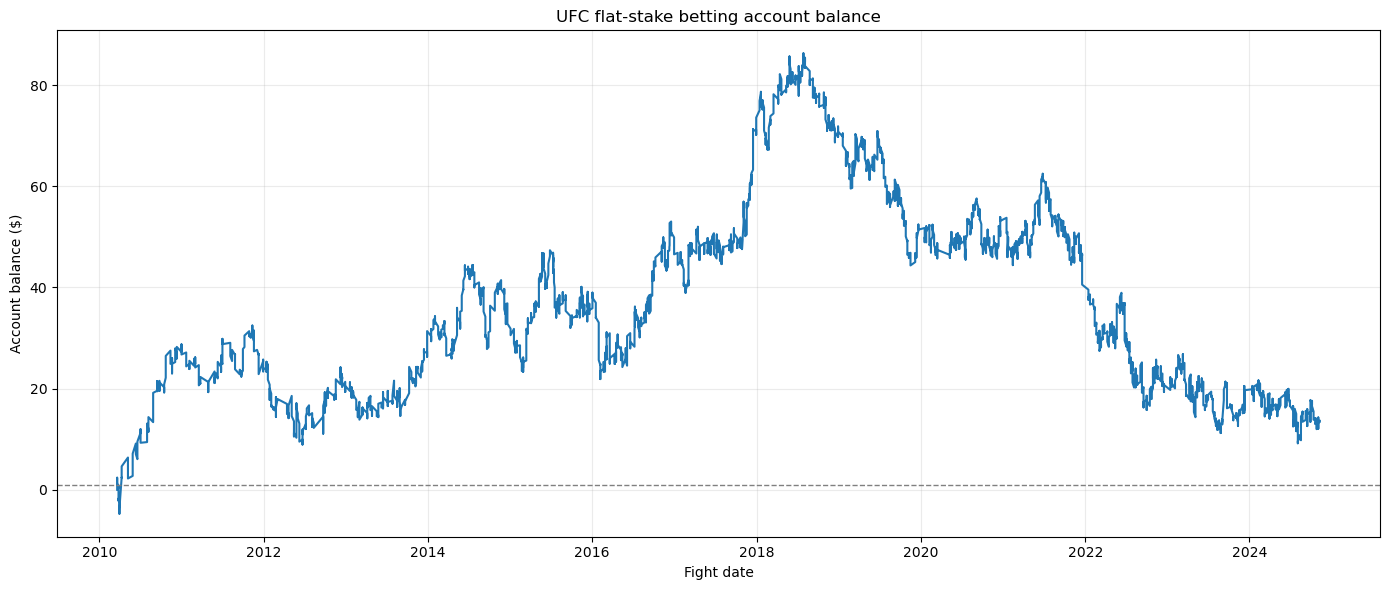

In [51]:
total_bets = len(results)
wins = int(results["bet_won"].sum())
losses = total_bets - wins
total_profit = results["net_profit"].sum()
summary = pd.Series(
    {
        "starting_balance": INITIAL_BALANCE,
        "stake_per_bet": STAKE,
        "total_bets": total_bets,
        "wins": wins,
        "losses": losses,
        "win_rate": wins / total_bets if total_bets else np.nan,
        "total_profit": total_profit,
        "final_balance": results["balance_after"].iloc[-1],
        "lowest_balance": results["balance_after"].min(),
    },
    name="value",
)
display(summary.to_frame())

plt.figure(figsize=(14, 6))
plt.plot(results["date"], results["balance_after"], linewidth=1.5)
plt.axhline(INITIAL_BALANCE, color="gray", linestyle="--", linewidth=1)
plt.title("UFC flat-stake betting account balance")
plt.xlabel("Fight date")
plt.ylabel("Account balance ($)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [57]:
# Inspect every simulated bet, including the selected side, odds, result, and balance.
results[[
    "bet_number", "date", "fight_id", "R_fighter", "B_fighter",
    "probability_red", "bet_side", "bet_odds", "Winner",
    "bet_won", "net_profit", "balance_before", "balance_after",
]].tail(5)

,bet_number,date,fight_id,R_fighter,B_fighter,probability_red,bet_side,bet_odds,Winner,bet_won,net_profit,balance_before,balance_after
3557,3558,2024-11-02,876,Caio Machado,Brendson Ribeiro,0.521891,Red,-192.0,Blue,False,-1.000000,13.097585,12.097585
3558,3559,2024-11-02,877,Marc-Andre Barriault,Dustin Stoltzfus,0.351235,Blue,220.0,Blue,True,2.200000,12.097585,14.297585
3559,3560,2024-11-02,879,Mike Malott,Trevin Giles,0.473860,Blue,295.0,Red,False,-1.000000,14.297585,13.297585
3560,3561,2024-11-09,862,Neil Magny,Carlos Prates,0.332608,Blue,-800.0,Blue,True,0.125000,13.297585,13.422585
3561,3562,2024-11-09,863,Luana Pinheiro,Gillian Robertson,0.260304,Blue,-470.0,Blue,True,0.212766,13.422585,13.635351


## Informed betting using model probability versus bookmaker odds

The bookmaker probabilities below are the raw implied probabilities from the American odds, so they include the bookmaker's vig. A bet is placed only when the model probability is greater than the side's break-even probability. The side with the greater positive expected value is selected, so there is never more than one bet on a fight.

In [53]:
BETTING_MODE = "underdogs"  # Choose: "underdogs", "favorites", or "both".


In [ ]:





def american_implied_probability(american_odds):
    odds = pd.to_numeric(american_odds, errors="coerce")
    return np.where(
        odds > 0,
        100.0 / (odds + 100.0),
        np.where(odds < 0, abs(odds) / (abs(odds) + 100.0), np.nan),
    )


def american_decimal_odds(american_odds):
    odds = pd.to_numeric(american_odds, errors="coerce")
    return np.where(
        odds > 0,
        1.0 + odds / 100.0,
        np.where(odds < 0, 1.0 + 100.0 / abs(odds), np.nan),
    )


informed_results = predictions.copy()
informed_results["market_red_prob_with_vig"] = american_implied_probability(informed_results["RedOdds"])
informed_results["market_blue_prob_with_vig"] = american_implied_probability(informed_results["BlueOdds"])
informed_results["bookmaker_overround"] = (
    informed_results["market_red_prob_with_vig"]
    + informed_results["market_blue_prob_with_vig"]
    - 1.0
)
informed_results["model_probability_blue"] = 1.0 - informed_results["probability_red"]

informed_results["red_edge"] = (
    informed_results["probability_red"]
    - informed_results["market_red_prob_with_vig"]
)
informed_results["blue_edge"] = (
    informed_results["model_probability_blue"]
    - informed_results["market_blue_prob_with_vig"]
)

informed_results["red_expected_value"] = (
    informed_results["probability_red"]
    * american_decimal_odds(informed_results["RedOdds"])
    - 1.0
)
informed_results["blue_expected_value"] = (
    informed_results["model_probability_blue"]
    * american_decimal_odds(informed_results["BlueOdds"])
    - 1.0
)

# Positive expected value means the model probability beats the
# bookmaker's vig-inclusive break-even probability.
if BETTING_MODE not in {"underdogs", "favorites", "both"}:
    raise ValueError("BETTING_MODE must be 'underdogs', 'favorites', or 'both'.")

red_is_underdog = informed_results["RedOdds"] > 0
blue_is_underdog = informed_results["BlueOdds"] > 0
red_is_favorite = informed_results["RedOdds"] < 0
blue_is_favorite = informed_results["BlueOdds"] < 0

red_allowed = (BETTING_MODE == "both") | (
    (BETTING_MODE == "underdogs") & red_is_underdog
) | ((BETTING_MODE == "favorites") & red_is_favorite)
blue_allowed = (BETTING_MODE == "both") | (
    (BETTING_MODE == "underdogs") & blue_is_underdog
) | ((BETTING_MODE == "favorites") & blue_is_favorite)

red_candidate_ev = informed_results["red_expected_value"].where(red_allowed, -np.inf)
blue_candidate_ev = informed_results["blue_expected_value"].where(blue_allowed, -np.inf)
red_is_best_value = (red_candidate_ev > 0) & (red_candidate_ev >= blue_candidate_ev)
blue_is_best_value = (blue_candidate_ev > 0) & (blue_candidate_ev > red_candidate_ev)
informed_results["bet_side"] = np.select(
    [red_is_best_value, blue_is_best_value],
    ["Red", "Blue"],
    default="No bet",
)
informed_results["bet_placed"] = informed_results["bet_side"] != "No bet"
informed_results["bet_odds"] = np.where(
    informed_results["bet_side"] == "Red",
    informed_results["RedOdds"],
    np.where(informed_results["bet_side"] == "Blue", informed_results["BlueOdds"], np.nan),
)

# Optional consistency check against RedProbOdds/BlueProbOdds in the CSV.
if {"RedProbOdds", "BlueProbOdds"}.issubset(odds.columns):
    red_probability_difference = (
        american_implied_probability(odds["RedOdds"])
        - pd.to_numeric(odds["RedProbOdds"], errors="coerce")
    ).abs().max()
    blue_probability_difference = (
        american_implied_probability(odds["BlueOdds"])
        - pd.to_numeric(odds["BlueProbOdds"], errors="coerce")
    ).abs().max()
    print(f"Maximum Red implied-probability difference: {red_probability_difference:.8f}")
    print(f"Maximum Blue implied-probability difference: {blue_probability_difference:.8f}")

informed_results[[
    "date", "R_fighter", "B_fighter", "probability_red",
    "market_red_prob_with_vig", "market_blue_prob_with_vig",
    "bookmaker_overround", "red_expected_value",
    "blue_expected_value", "bet_side",
]].head(20)

Maximum Red implied-probability difference: 0.00005000
Maximum Blue implied-probability difference: 0.00005000


,value
starting_balance,1.0
betting_mode,underdogs
stake_per_bet,1.0
eligible_fights_with_odds,3562
bets_placed,2458
no_bet_fights,1104
wins,819
losses,1639
win_rate_on_bets,0.333198
total_profit,-93.53


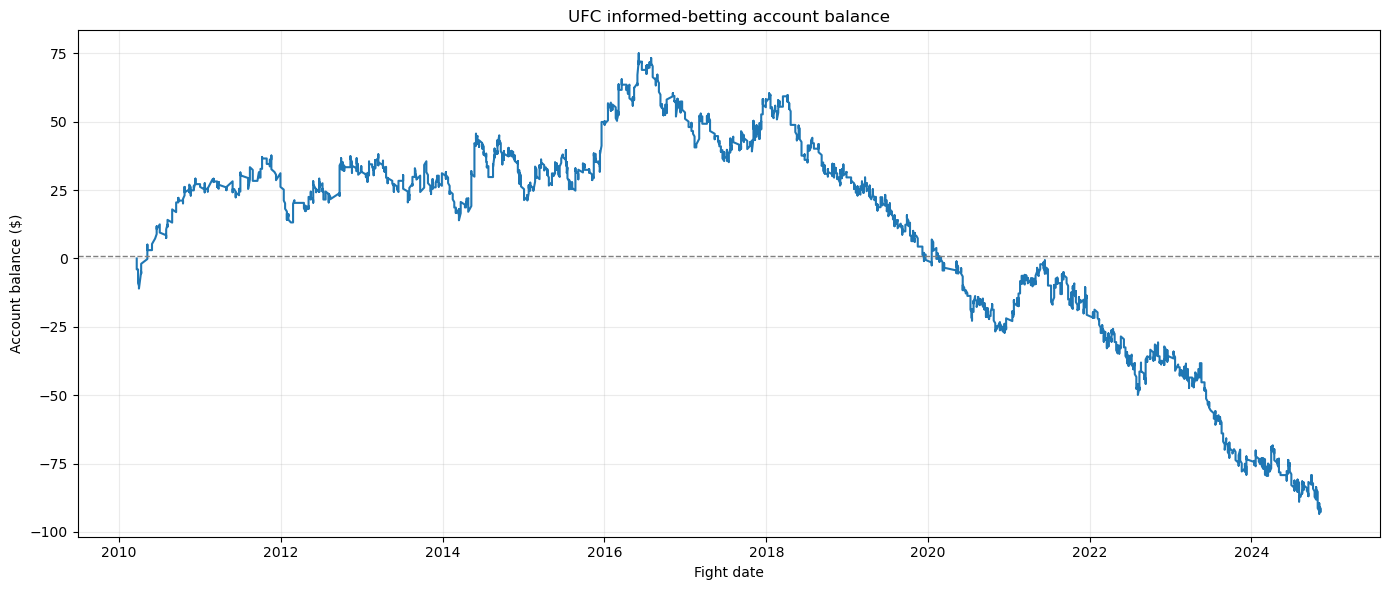

In [55]:
informed_results["bet_won"] = (
    informed_results["bet_placed"]
    & (informed_results["Winner"] == informed_results["bet_side"])
)
informed_results["net_profit"] = 0.0

winning_bets = informed_results["bet_placed"] & informed_results["bet_won"]
losing_bets = informed_results["bet_placed"] & ~informed_results["bet_won"]
informed_results.loc[winning_bets, "net_profit"] = informed_results.loc[winning_bets, "bet_odds"].map(
    lambda odds: winning_net_profit(float(odds), STAKE)
)
informed_results.loc[losing_bets, "net_profit"] = -STAKE

informed_results["bet_number"] = informed_results["bet_placed"].cumsum()
informed_results["balance_before"] = (
    INITIAL_BALANCE
    + informed_results["net_profit"].cumsum().shift(fill_value=0)
)
informed_results["balance_after"] = INITIAL_BALANCE + informed_results["net_profit"].cumsum()

informed_bet_count = int(informed_results["bet_placed"].sum())
informed_wins = int(informed_results["bet_won"].sum())
informed_summary = pd.Series(
    {
        "starting_balance": INITIAL_BALANCE,
        "betting_mode": BETTING_MODE,
        "stake_per_bet": STAKE,
        "eligible_fights_with_odds": len(informed_results),
        "bets_placed": informed_bet_count,
        "no_bet_fights": int((~informed_results["bet_placed"]).sum()),
        "wins": informed_wins,
        "losses": informed_bet_count - informed_wins,
        "win_rate_on_bets": informed_wins / informed_bet_count if informed_bet_count else np.nan,
        "total_profit": informed_results["net_profit"].sum(),
        "final_balance": informed_results["balance_after"].iloc[-1],
        "lowest_balance": informed_results["balance_after"].min(),
        "average_bookmaker_overround": informed_results["bookmaker_overround"].mean(),
    },
    name="value",
)
display(informed_summary.to_frame())

plt.figure(figsize=(14, 6))
plt.plot(informed_results["date"], informed_results["balance_after"], linewidth=1.5)
plt.axhline(INITIAL_BALANCE, color="gray", linestyle="--", linewidth=1)
plt.title("UFC informed-betting account balance")
plt.xlabel("Fight date")
plt.ylabel("Account balance ($)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [56]:
informed_results[[
    "bet_number", "date", "fight_id", "R_fighter", "B_fighter",
    "probability_red", "market_red_prob_with_vig",
    "market_blue_prob_with_vig", "red_expected_value",
    "blue_expected_value", "bet_side", "bet_odds",
    "Winner", "bet_won", "net_profit", "balance_after",
]].tail(20)

,bet_number,date,fight_id,R_fighter,B_fighter,probability_red,market_red_prob_with_vig,market_blue_prob_with_vig,red_expected_value,blue_expected_value,bet_side,bet_odds,Winner,bet_won,net_profit,balance_after
3542,2443,2024-10-19,907,Jessica Penne,Elise Reed,0.418248,0.344828,0.696970,0.212921,-0.165313,Red,190.0,Blue,False,-1.0,-87.63
3543,2444,2024-10-19,909,Austen Lane,Robelis Despaigne,0.455440,0.232558,0.809524,0.958390,-0.327308,Red,330.0,Red,True,3.3,-84.33
3544,2445,2024-10-26,886,Magomed Ankalaev,Aleksandar Rakic,0.690520,0.772727,0.270270,-0.106387,0.145078,Blue,270.0,Red,False,-1.0,-85.33
3545,2446,2024-10-26,887,Lerone Murphy,Dan Ige,0.641327,0.772727,0.270270,-0.170047,0.327089,Blue,270.0,Red,False,-1.0,-86.33
3546,2446,2024-10-26,888,Robert Whittaker,Khamzat Chimaev,0.330084,0.333333,0.710145,-0.009747,-0.056649,No bet,NaN,Blue,False,0.0,-86.33
3547,2447,2024-10-26,889,Ilia Topuria,Max Holloway,0.449842,0.753086,0.289855,-0.402669,0.898045,Blue,245.0,Red,False,-1.0,-87.33
3548,2447,2024-10-26,891,Mateusz Rebecki,Myktybek Orolbai,0.262206,0.317460,0.726027,-0.174052,0.016207,No bet,NaN,Red,False,0.0,-87.33
3549,2447,2024-10-26,892,Shara Magomedov,Armen Petrosyan,0.597730,0.624060,0.416667,-0.042192,-0.034551,No bet,NaN,Red,False,0.0,-87.33
3550,2448,2024-10-26,893,Abus Magomedov,Brunno Ferreira,0.526520,0.607843,0.434783,-0.133790,0.089004,Blue,130.0,Red,False,-1.0,-88.33
3551,2449,2024-10-26,894,Kennedy Nzechukwu,Chris Barnett,0.663297,0.888889,0.153846,-0.253791,1.188572,Blue,550.0,Red,False,-1.0,-89.33
